# 02 – Explore the Fluo-N2DL-HeLa dataset

**Purpose:** Load one time-lapse sequence with its annotations, check image properties,
and inspect raw data, gold truth and silver truth in napari. Completes stage 1 ("inspect data").

**Input:** `data/raw/Fluo-N2DL-HeLa/` (CTC training data, sequences `01` and `02`)
**Output:** nothing saved yet – understanding of the data and its annotations.

**Dataset (from the CTC website):** HeLa cells stably expressing H2B-GFP (Mitocheck Consortium),
Olympus IX81, 10x/0.4, pixel size 0.645 µm, time step 30 min.

### Folder structure
| Folder | Content |
|---|---|
| `01/`, `02/` | raw images `t000.tif` … `t091.tif` (92 frames) |
| `0X_GT/SEG/` | **gold truth** segmentation – manual, only selected frames (`man_segTTT.tif`, TTT = frame) |
| `0X_GT/TRA/` | tracking reference for all frames (`man_trackTTT.tif`) + lineage table `man_track.txt` |
| `0X_ST/SEG/` | **silver truth** segmentation – computer-generated, all frames |

**Rule for later:** train on silver truth, evaluate only on gold truth (otherwise the evaluation is circular).

## 1. Imports and settings
`Path` handles file paths independent of the operating system.
The notebook lives in `notebooks/`, so the data folder is one level up (`..`).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile

DATA = Path("../data/raw/Fluo-N2DL-HeLa")
SEQ = "01"              # sequence to explore; change to "02" for the second one

PIXEL_SIZE_UM = 0.645   # µm per pixel (CTC website)
FRAME_INTERVAL_MIN = 30 # minutes between frames (CTC website)

print("data folder exists:", DATA.exists())
print("subfolders:", sorted(p.name for p in DATA.iterdir()))

data folder exists: True
subfolders: ['01', '01_GT', '01_ST', '02', '02_GT', '02_ST']


## 2. Load the raw time-lapse
All frames are read and stacked into one 3D array with axes **(time, y, x)** –
the same layout as a stack in Fiji. `sorted()` matters: without it, the file order is not guaranteed.

In [2]:
raw_files = sorted((DATA / SEQ).glob("t*.tif"))
raw = np.stack([tifffile.imread(f) for f in raw_files])

print("frames:", len(raw_files))
print("shape (t, y, x):", raw.shape)
print("dtype:", raw.dtype)
print("min/max:", raw.min(), raw.max())
print(f"field of view: {raw.shape[2] * PIXEL_SIZE_UM:.0f} x {raw.shape[1] * PIXEL_SIZE_UM:.0f} µm")
print(f"duration: {(len(raw_files) - 1) * FRAME_INTERVAL_MIN / 60:.1f} h")

frames: 92
shape (t, y, x): (92, 700, 1100)
dtype: uint16
min/max: 32995 36863
field of view: 710 x 452 µm
duration: 45.5 h


## 3. Intensity range and saturation
For 16-bit data the ceiling is 65535. Percentiles show where most of the signal lies –
useful for display contrast (like *Auto* in Fiji's Brightness/Contrast) and for normalisation later.

In [3]:
dtype_max = np.iinfo(raw.dtype).max
n_sat = np.sum(raw == dtype_max)
print(f"dtype maximum: {dtype_max} | saturated pixels: {n_sat} ({100 * n_sat / raw.size:.4f} %)")

p1, p99 = np.percentile(raw, [1, 99.8])
print(f"1st / 99.8th percentile: {p1:.0f} / {p99:.0f}")

dtype maximum: 65535 | saturated pixels: 0 (0.0000 %)
1st / 99.8th percentile: 33035 / 34418


## 4. Mean intensity over time
A steady decline would indicate photobleaching; jumps can indicate focus or illumination changes.
Relevant later because intensity-based steps (and the network) see a different image over time.

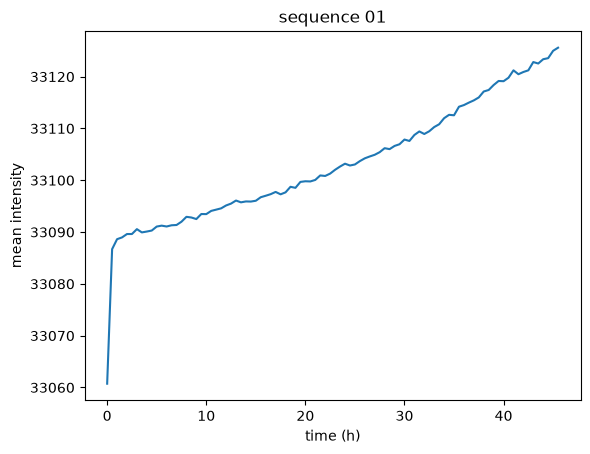

In [4]:
mean_per_frame = raw.mean(axis=(1, 2))   # average over y and x → one value per frame
hours = np.arange(len(mean_per_frame)) * FRAME_INTERVAL_MIN / 60

plt.plot(hours, mean_per_frame)
plt.xlabel("time (h)")
plt.ylabel("mean intensity")
plt.title(f"sequence {SEQ}")
plt.show()

## 5. Load the annotations
- **Silver truth (ST):** one label image per frame → stack of the same shape as `raw`.
- **Gold truth (GT/SEG):** only some frames are annotated. To overlay them in napari, they are placed
  into an empty stack of the full length; frames without annotation stay 0.
- **Tracking markers (GT/TRA):** one label image per frame; the label value is the track ID.

In [5]:
def frame_number(path):
    """Extract the frame index from names like man_seg012.tif or man_track012.tif."""
    return int("".join(c for c in path.stem if c.isdigit()))

# silver truth – all frames
st_files = sorted((DATA / f"{SEQ}_ST" / "SEG").glob("man_seg*.tif"))
st = np.stack([tifffile.imread(f) for f in st_files])

# gold truth – selected frames only, placed into a full-length stack
gt_files = sorted((DATA / f"{SEQ}_GT" / "SEG").glob("man_seg*.tif"))
gt_frames = [frame_number(f) for f in gt_files]
gt = np.zeros_like(st)
for f, t in zip(gt_files, gt_frames):
    gt[t] = tifffile.imread(f)

# tracking markers – all frames
tra_files = sorted((DATA / f"{SEQ}_GT" / "TRA").glob("man_track*.tif"))
tra = np.stack([tifffile.imread(f) for f in tra_files])

print("ST:", st.shape, st.dtype, "| frames:", len(st_files))
print("GT:", len(gt_files), "annotated frames:", gt_frames)
print("TRA:", tra.shape, tra.dtype, "| frames:", len(tra_files))

ST: (92, 700, 1100) uint16 | frames: 92
GT: 28 annotated frames: [12, 13, 14, 15, 20, 21, 22, 23, 25, 29, 38, 39, 40, 44, 50, 51, 52, 53, 54, 55, 62, 76, 77, 78, 79, 80, 81, 88]
TRA: (92, 700, 1100) uint16 | frames: 92


## 6. Is every nucleus annotated in the gold truth?
Compare the number of objects per frame between gold truth and silver truth on the GT frames.
If GT has clearly fewer objects, the gold truth is **partial** (only some nuclei annotated) –
this changes how the evaluation must be done (unannotated nuclei must not count as false positives).

In [6]:
def n_objects(label_img):
    """Number of distinct labels, excluding background (0)."""
    return len(np.unique(label_img)) - (1 if 0 in label_img else 0)

counts = pd.DataFrame({
    "frame": gt_frames,
    "n_gold": [n_objects(gt[t]) for t in gt_frames],
    "n_silver": [n_objects(st[t]) for t in gt_frames],
    "n_tra_markers": [n_objects(tra[t]) for t in gt_frames],
})
counts["gold_vs_silver"] = (counts["n_gold"] / counts["n_silver"]).round(2)
print(counts.to_string(index=False))

 frame  n_gold  n_silver  n_tra_markers  gold_vs_silver
    12       2        56             57            0.04
    13      59        59             60            1.00
    14       4        61             61            0.07
    15       8        61             62            0.13
    20      11        64             64            0.17
    21       3        66             66            0.05
    22       9        67             67            0.13
    23      12        70             70            0.17
    25       5        69             69            0.07
    29       7        72             72            0.10
    38      14        82             82            0.17
    39      13        82             83            0.16
    40       9        85             86            0.11
    44      14        96             97            0.15
    50       1       109            109            0.01
    51       3       109            110            0.03
    52     110       113            113         

## 7. Lineage table `man_track.txt`
Each row is one track: **label, first frame, last frame, parent** (parent 0 = no mother cell,
e.g. present from the start or entering the field of view).
A cell that divides ends, and two daughters with its label as parent start in the next frame.

In [7]:
tracks = pd.read_csv(DATA / f"{SEQ}_GT" / "TRA" / "man_track.txt",
                     sep=r"\s+", header=None, names=["label", "begin", "end", "parent"])
tracks["length_frames"] = tracks["end"] - tracks["begin"] + 1

daughters_per_parent = tracks.loc[tracks["parent"] > 0, "parent"].value_counts()

print("tracks:", len(tracks))
print("tracks with a parent:", (tracks["parent"] > 0).sum())
print("divisions (parents with ≥2 daughters):", (daughters_per_parent >= 2).sum())
print()
print(tracks.head(10).to_string(index=False))

tracks: 265
tracks with a parent: 188
divisions (parents with ≥2 daughters): 94

 label  begin  end  parent  length_frames
     1      0   30       0             31
     8     31   91       1             61
     9     31   91       1             61
    10      0    4       0              5
    12      0   38       0             39
    14     39   91      12             53
    15     39   91      12             53
    16      0   22       0             23
    18     23   91      16             69
    19     23   91      16             69


## 8. View everything in napari
Layers (top to bottom in the layer list): tracking markers, gold truth, silver truth, raw.
Toggle layers with the eye icon, scroll through time with the slider at the bottom.

What to look for:
- How do GT and ST outlines differ (shape, size, touching nuclei)?
- Are there nuclei without GT label in the annotated frames (→ see step 6)?
- Find a division (e.g. track 1 ending at frame 30 in sequence 01) and look at the frames around it.
- TRA markers are not full outlines – check what they look like.

In [8]:
%gui qt
import napari

viewer = napari.Viewer()
viewer.add_image(raw, name=f"raw {SEQ}", colormap="gray", contrast_limits=(p1, p99))
viewer.add_labels(st, name="silver truth")
viewer.add_labels(gt, name="gold truth")
viewer.add_labels(tra, name="TRA markers", visible=False)

<Labels layer 'TRA markers' at 0x16cd18530>

## Results and observations (2026-10-30, sequence 01)

- **Image properties:** 92 frames, 700 × 1100 px (710 × 452 µm), uint16; values 32995–36863
  (camera offset, signal uses only a few thousand grey levels); no saturation.
  Display contrast set to 1st/99.8th percentile (33035/34418).
- **Intensity over time:** …
- **Gold truth is partial:** only frames 13 (59/59) and 52 (110/113) are fully annotated;
  the other 26 GT frames contain 1–35 nuclei out of >100.
  → Precision/recall/F1 only on frames 13 and 52; on partial frames only IoU of annotated nuclei.
- **Lineage:** 265 tracks, 94 divisions (each with exactly 2 daughters).
  Number of nuclei rises from ~56 to ~134. After division, daughters get new labels (CTC convention).
- **Visual impressions:** nuclear brightness varies with cell cycle (H2B-GFP): dim after division,
  brighter later (likely S phase), very bright and compact during mitosis.

## 9. Background vs. nuclei over time
The whole-image mean mixes background and nuclei. Using the silver-truth masks, both are measured
separately, together with the fraction of the image covered by nuclei.

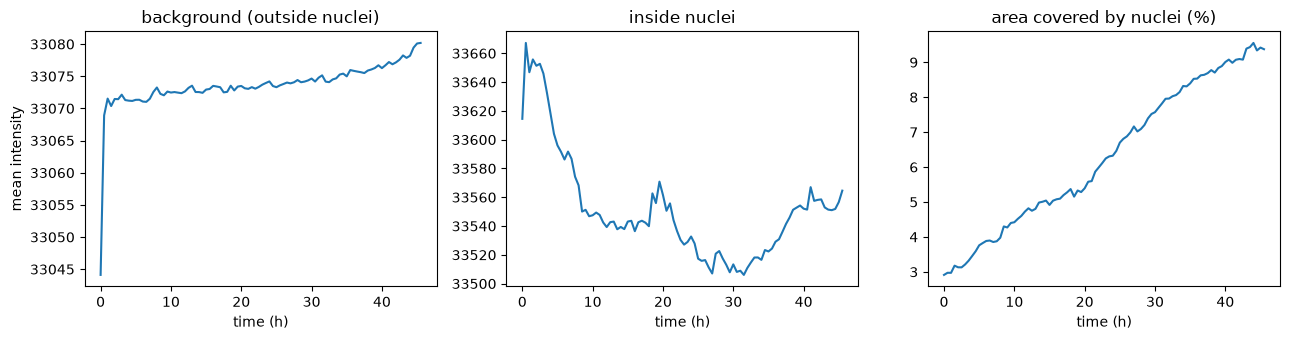

In [9]:
bg_mean = np.array([raw[t][st[t] == 0].mean() for t in range(len(raw))])
fg_mean = np.array([raw[t][st[t] > 0].mean() for t in range(len(raw))])
area_fraction = (st > 0).mean(axis=(1, 2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(hours, bg_mean); axes[0].set_title("background (outside nuclei)")
axes[1].plot(hours, fg_mean); axes[1].set_title("inside nuclei")
axes[2].plot(hours, 100 * area_fraction); axes[2].set_title("area covered by nuclei (%)")
for ax in axes:
    ax.set_xlabel("time (h)")
axes[0].set_ylabel("mean intensity")
plt.tight_layout(); plt.show()

## 10. Intensity per nucleus
Hypothesis: two intensity groups reflect DNA content (G1 = 2n, G2 = 4n → about 2× more H2B-GFP).
Per nucleus and frame: subtract the frame's background (median outside nuclei), then measure
area and mean intensity. Integrated intensity = mean × area (total H2B-GFP in the nucleus).
Note: each nucleus is measured in many frames → measurements are not independent (matters for statistics later).

In [10]:
from skimage.measure import regionprops_table

rows = []
for t in range(len(raw)):
    bg = np.median(raw[t][st[t] == 0])                 # background level of this frame
    img = raw[t].astype(np.float64) - bg               # float: avoids uint16 wrap-around below 0
    props = regionprops_table(st[t], intensity_image=img,
                              properties=["label", "area", "intensity_mean"])
    df_t = pd.DataFrame(props)
    df_t["frame"] = t
    rows.append(df_t)

nuc = pd.concat(rows, ignore_index=True)
nuc["integrated"] = nuc["intensity_mean"] * nuc["area"]
print("measurements:", len(nuc), "| non-positive integrated:", (nuc["integrated"] <= 0).sum())
print(nuc[["area", "intensity_mean", "integrated"]].describe().round(1))

measurements: 8602 | non-positive integrated: 0
         area  intensity_mean  integrated
count  8602.0          8602.0      8602.0
mean    518.5           470.1    245434.6
std     164.2           302.7    177331.6
min      31.0             5.3       397.0
25%     410.0           242.2    115843.5
50%     524.0           429.5    206106.5
75%     615.0           638.4    337096.2
max    1415.0          2020.5   1200878.0


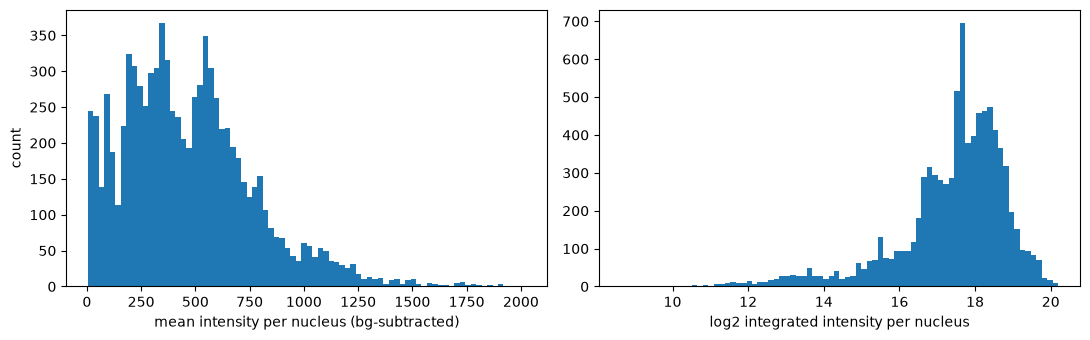

In [11]:
pos = nuc[nuc["integrated"] > 0]   # log2 needs positive values
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(pos["intensity_mean"], bins=80)
axes[0].set_xlabel("mean intensity per nucleus (bg-subtracted)")
axes[0].set_ylabel("count")
axes[1].hist(np.log2(pos["integrated"]), bins=80)
axes[1].set_xlabel("log2 integrated intensity per nucleus")
plt.tight_layout(); plt.show()

## 11. Check the spike at log2 ≈ 17.6
A single histogram bin with ~700 measurements is biologically implausible → check whether the
same objects repeat (identical area / frames / labels) before fitting any model.

In [13]:
log_int = np.log2(nuc["integrated"])
spike = nuc[(log_int > 17.5) & (log_int < 17.7)]

print("measurements in spike bin:", len(spike))
print("\nmost frequent areas:\n", spike["area"].value_counts().head())
print("\nmost frequent labels:\n", spike["label"].value_counts().head())
print("\nframes covered:", spike["frame"].nunique(), "of", nuc["frame"].nunique())

measurements in spike bin: 967

most frequent areas:
 area
575.0    9
394.0    7
593.0    7
594.0    7
558.0    7
Name: count, dtype: int64

most frequent labels:
 label
36     52
163    41
160    41
199    35
265    35
Name: count, dtype: int64

frames covered: 88 of 92


## 12. Link each measurement to its track
Segmentation labels are assigned per frame; the identity of a cell over time is given by the
tracking markers (TRA). For each silver-truth object, the TRA marker inside it gives the track ID
(0 = no marker inside, e.g. a fragment). If two markers fall into one object (merge), the larger ID is taken.

In [14]:
rows = []
for t in range(len(st)):
    # the TRA image is used as "intensity" image: its max inside each ST object = track ID
    p = regionprops_table(st[t], intensity_image=tra[t], properties=["label", "intensity_max"])
    rows.append(pd.DataFrame({"frame": t, "label": p["label"],
                              "track": p["intensity_max"].astype(int)}))
link = pd.concat(rows, ignore_index=True)

nuc = nuc.drop(columns="track", errors="ignore").merge(link, on=["frame", "label"], how="left")
print("measurements with a track ID:", (nuc["track"] > 0).sum(), "of", len(nuc))

measurements with a track ID: 8602 of 8602


## 13. H2B-GFP content over complete cell cycles
A complete cycle = a track that was born by division (has a parent) AND divides again (has ≥2 daughters).
Hypothesis: integrated intensity doubles from birth to division (DNA replication → H2B incorporation).
Start and end values are medians of the first and last 3 frames (less sensitive to single-frame noise).
Each cell is shown relative to its own intensity at birth (log2 ratio: 0 = start, +1 = doubled) and on a
normalised time axis (cell-cycle fraction). This removes cell-to-cell differences in expression level,
which are shown separately on the right.

cell cycles used: 56


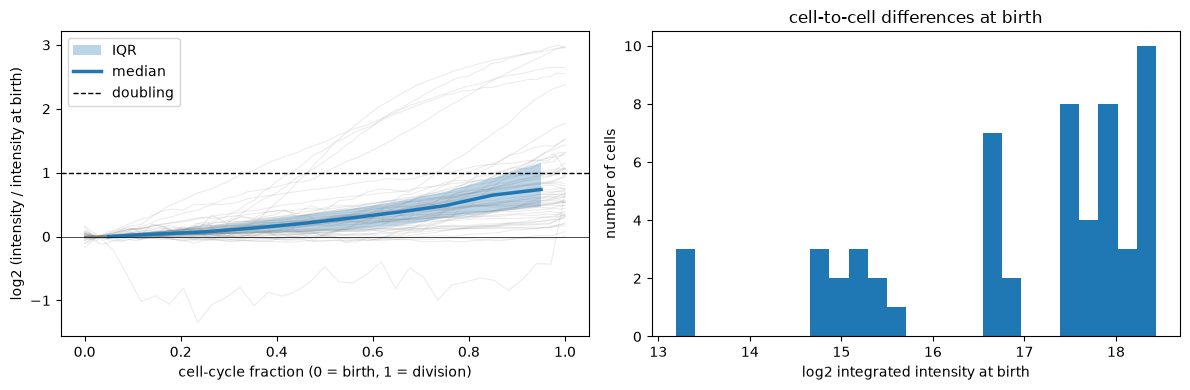

end/start ratio: median 1.59, IQR 1.34–2.12 (n = 56)


In [16]:
children = tracks.loc[tracks["parent"] > 0, "parent"].value_counts()
dividing = set(children[children >= 2].index)
complete = tracks[(tracks["parent"] > 0) & (tracks["label"].isin(dividing))]

# per complete cycle: time as cycle fraction, intensity relative to the cell's own start
cyc = []
for _, tr in complete.iterrows():
    d = nuc[nuc["track"] == tr["label"]].sort_values("frame").copy()
    if len(d) < 6:
        continue
    d["cycle_fraction"] = (d["frame"] - tr["begin"]) / max(tr["end"] - tr["begin"], 1)
    start = d["integrated"].iloc[:3].median()
    d["log2_rel"] = np.log2(d["integrated"] / start)   # 0 = start level, +1 = doubled
    d["log2_start"] = np.log2(start)
    cyc.append(d)
cyc = pd.concat(cyc, ignore_index=True)
print("cell cycles used:", cyc["track"].nunique())

# median and quartiles in 10 bins along the cycle
cyc["bin"] = pd.cut(cyc["cycle_fraction"], bins=np.linspace(0, 1, 11), include_lowest=True)
summary = cyc.groupby("bin", observed=True)["log2_rel"].quantile([0.25, 0.5, 0.75]).unstack()
centers = np.linspace(0.05, 0.95, 10)[: len(summary)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
for _, d in cyc.groupby("track"):
    ax.plot(d["cycle_fraction"], d["log2_rel"], color="grey", alpha=0.15, lw=0.8)
ax.fill_between(centers, summary[0.25], summary[0.75], alpha=0.3, label="IQR")
ax.plot(centers, summary[0.5], lw=2.5, label="median")
ax.axhline(1, ls="--", color="k", lw=1, label="doubling")
ax.axhline(0, color="k", lw=0.5)
ax.set_xlabel("cell-cycle fraction (0 = birth, 1 = division)")
ax.set_ylabel("log2 (intensity / intensity at birth)")
ax.legend()

ax = axes[1]
start_per_track = cyc.groupby("track")["log2_start"].first()
ax.hist(start_per_track.dropna(), bins=25)
ax.set_xlabel("log2 integrated intensity at birth")
ax.set_ylabel("number of cells")
ax.set_title("cell-to-cell differences at birth")

plt.tight_layout(); plt.show()

end_rel = cyc.groupby("track").apply(lambda d: d["log2_rel"].iloc[-3:].median(), include_groups=False)
ratio = 2 ** end_rel
print(f"end/start ratio: median {ratio.median():.2f}, "
      f"IQR {ratio.quantile(0.25):.2f}–{ratio.quantile(0.75):.2f} (n = {len(ratio)})")

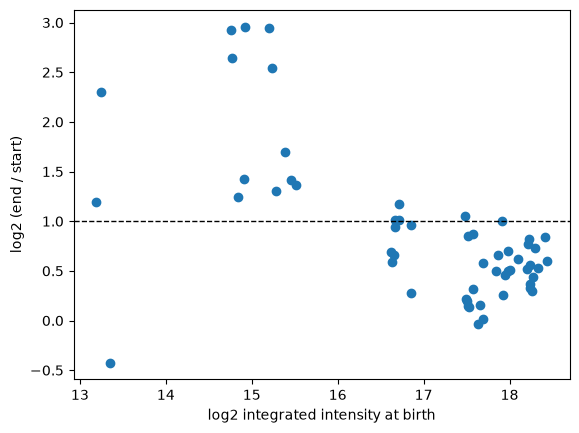

In [17]:
end_rel_df = pd.DataFrame({"log2_start": start_per_track, "log2_end_rel": end_rel})
plt.scatter(end_rel_df["log2_start"], end_rel_df["log2_end_rel"])
plt.axhline(1, ls="--", color="k", lw=1)
plt.xlabel("log2 integrated intensity at birth")
plt.ylabel("log2 (end / start)")
plt.show()

- **H2B-GFP over the cell cycle (56 complete cycles):** integrated intensity rises steadily from birth
  to division, median end/start ratio 1.59 (IQR 1.34–2.12) – less than the expected doubling.
  Possible causes: chromatin condensation around division affecting the masks, 2D widefield projection,
  background sensitivity of dim cells. Some cells rise 4–8× (implausible) → likely measurement artefacts.
- **Cell-to-cell differences:** intensity at birth varies >30× and clusters into groups, consistent with
  inherited expression levels in cell families. The two peaks in the intensity histogram therefore mix
  cell-cycle stage and between-cell expression differences.
- **Ratio depends on starting level:** dim cell families (log2 start < 16) mostly exceed doubling
  (up to 8×), bright families (> 16.5) mostly stay below it. A real DNA-content effect should not depend
  on expression level → most likely a measurement artefact (background subtraction / mask size at low signal).
- **Next (later):** repeat with own segmentation; mixed model in R with cell family as random effect.